<a href="https://colab.research.google.com/github/usman3721/AI-Reseach-MLC-Community/blob/main/yoruba_sib200_xlmr.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Yoruba Cross-Lingual Transfer & Data Efficiency (SIB-200)
**Question:** How many Yoruba examples does XLM-R need to reach good topic-classification performance, and does English data help?

**Runtime:** Runtime > Change runtime type > T4 GPU.

Conditions:
- **en+yo(n):** train on all English + n Yoruba examples (n=0 is zero-shot transfer)
- **yo-only(n):** train on n Yoruba examples only (no English)

In [ ]:
!pip install -q transformers datasets accelerate scikit-learn matplotlib pandas
from google.colab import drive
drive.mount('/content/drive')
import os
OUT = '/content/drive/MyDrive/yoruba_project'
os.makedirs(OUT, exist_ok=True)

Mounted at /content/drive


## 1. Load the data

In [ ]:
from datasets import load_dataset
en = load_dataset("Davlan/sib200", "eng_Latn")
yo = load_dataset("Davlan/sib200", "yor_Latn")
print(yo)
print(yo["train"][0])
# Check class balance - always look at your data first
import collections
print(collections.Counter(yo["train"]["category"]))

README.md:   0%|          | 0.00/47.9k [00:00<?, ?B/s]

train.tsv:   0%|          | 0.00/103k [00:00<?, ?B/s]

dev.tsv:   0%|          | 0.00/13.6k [00:00<?, ?B/s]

test.tsv:   0%|          | 0.00/30.1k [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

... (4 outputs left out)

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['index_id', 'category', 'text'],
        num_rows: 701
    })
    validation: Dataset({
        features: ['index_id', 'category', 'text'],
        num_rows: 99
    })
    test: Dataset({
        features: ['index_id', 'category', 'text'],
        num_rows: 204
    })
})
{'index_id': 431, 'category': 'geography', 'text': 'Orile ede Turkey je eyiti okun nla meta yi ka: okun Aegean ni apa iwo oorun, Okun Dudu ni ariwa ati Okun Medirettanean ni apa ila oorun.'}
Counter({'science/technology': 176, 'travel': 138, 'politics': 102, 'sports': 85, 'health': 77, 'entertainment': 65, 'geography': 58})


## 2. Tokenizer check (your first mini-experiment)
Tokens-per-word ("fertility") is a proxy for how well the tokenizer knows a language. Higher = worse fit.

In [ ]:
from transformers import AutoTokenizer
MODEL = "xlm-roberta-base"
MODEL2 = "Davlan/afro-xlmr-base"
tok = AutoTokenizer.from_pretrained(MODEL)

def fertility(texts, n=200):
    toks = words = 0
    for t in texts[:n]:
        toks += len(tok.tokenize(t)); words += len(t.split())
    return toks / words

print("English tokens/word:", round(fertility(en["train"]["text"]), 2))
print("Yoruba  tokens/word:", round(fertility(yo["train"]["text"]), 2))
print(tok.tokenize(yo["train"][0]["text"])[:40])

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

English tokens/word: 1.38
Yoruba  tokens/word: 2.73
['▁O', 'rile', '▁e', 'de', '▁Turkey', '▁je', '▁e', 'y', 'iti', '▁o', 'kun', '▁n', 'la', '▁meta', '▁yi', '▁ka', ':', '▁o', 'kun', '▁A', 'eg', 'ean', '▁ni', '▁apa', '▁i', 'wo', '▁oor', 'un', ',', '▁O', 'kun', '▁Du', 'du', '▁ni', '▁ar', 'iwa', '▁ati', '▁O', 'kun', '▁Medi']


## 3. Preprocessing

In [ ]:
labels = sorted(set(en["train"]["category"]))
label2id = {l: i for i, l in enumerate(labels)}
id2label = {i: l for l, i in label2id.items()}

def prep(ds):
    ds = ds.map(lambda b: {"label": [label2id[c] for c in b["category"]]}, batched=True)
    ds = ds.map(lambda b: tok(b["text"], truncation=True, max_length=128), batched=True)
    return ds.select_columns(["input_ids", "attention_mask", "label"])

en = {k: prep(v) for k, v in en.items()}
yo = {k: prep(v) for k, v in yo.items()}
print(labels)

Map:   0%|          | 0/701 [00:00<?, ? examples/s]

Map:   0%|          | 0/701 [00:00<?, ? examples/s]

Map:   0%|          | 0/99 [00:00<?, ? examples/s]

Map:   0%|          | 0/99 [00:00<?, ? examples/s]

Map:   0%|          | 0/204 [00:00<?, ? examples/s]

Map:   0%|          | 0/204 [00:00<?, ? examples/s]

... (3 outputs left out)

Map:   0%|          | 0/99 [00:00<?, ? examples/s]

Map:   0%|          | 0/204 [00:00<?, ? examples/s]

Map:   0%|          | 0/204 [00:00<?, ? examples/s]

['entertainment', 'geography', 'health', 'politics', 'science/technology', 'sports', 'travel']


## 4. Training + evaluation function
Metrics: accuracy and **macro-F1** (averages F1 over classes equally, so it is less misleading than accuracy if classes are imbalanced).

Caveat to discuss: the Yoruba *validation* set is used only to monitor training. We never select anything on the **test** set.

In [ ]:
import math
import numpy as np, torch
from sklearn.metrics import accuracy_score, f1_score
from datasets import concatenate_datasets
from transformers import (AutoModelForSequenceClassification, TrainingArguments,
                          Trainer, DataCollatorWithPadding, set_seed)

def metrics(p):
    preds = p.predictions.argmax(-1)
    return {"accuracy": accuracy_score(p.label_ids, preds),
            "macro_f1": f1_score(p.label_ids, preds, average="macro")}

def run_experiment(model_name, n_yo, use_english, seed, epochs=5, lr=2e-5):
    set_seed(seed)

    # 1. Build the training set
    parts = []
    if use_english: parts.append(en["train"])
    if n_yo > 0: parts.append(yo["train"].shuffle(seed=seed).select(range(n_yo)))
    train = concatenate_datasets(parts).shuffle(seed=seed)

    # 2. Compute warmup steps (needs `train` and `epochs`, so it lives here)
    batch_size = 16
    steps_per_epoch = math.ceil(len(train) / batch_size)
    total_steps = steps_per_epoch * epochs
    warmup_steps = int(0.1 * total_steps)   # 10% warmup

    # 3. Load the model
    model = AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=len(labels), id2label=id2label, label2id=label2id)

    # 4. Training settings
    args = TrainingArguments(
        output_dir="/content/tmp", num_train_epochs=epochs, learning_rate=lr,
        per_device_train_batch_size=batch_size, per_device_eval_batch_size=64,
        warmup_steps=warmup_steps, weight_decay=0.01, eval_strategy="epoch",
        save_strategy="no", fp16=torch.cuda.is_available(),
        report_to="none", seed=seed, logging_steps=50)

    # 5. Trainer (this block was missing in your version)
    trainer = Trainer(
        model=model, args=args, train_dataset=train,
        eval_dataset=yo["validation"],
        data_collator=DataCollatorWithPadding(tok),
        compute_metrics=metrics)

    # 6. Train, then evaluate once on the held-out Yoruba test set
    trainer.train()
    res = trainer.evaluate(yo["test"], metric_key_prefix="test")

    # 7. Free GPU memory
    del model, trainer; torch.cuda.empty_cache()
    return {"model": model_name, "n_yo": n_yo, "use_english": use_english, "seed": seed,
            "test_acc": res["test_accuracy"], "test_f1": res["test_macro_f1"]}

## 5. Smoke test (run this first, ~2 min)
Zero-shot: English only, evaluate on Yoruba.

In [ ]:
print(run_experiment(MODEL, n_yo=0, use_english=True, seed=0))

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,No log,1.856761,0.272727,0.086633
2,1.851587,1.853725,0.333333,0.257522
3,1.113373,2.032777,0.393939,0.308717
4,0.568856,1.977370,0.383838,0.343408
5,0.395741,2.084552,0.383838,0.324902


Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
0.395741,2.112498,5,0.367647,0.294549


{'model': 'xlm-roberta-base', 'n_yo': 0, 'use_english': True, 'seed': 0, 'test_acc': 0.36764705882352944, 'test_f1': 0.29454854728575014}


## 6. Full grid
Start with `SEEDS = [0]` to check everything works, then use `[0, 1, 2]`. Results are saved to Drive after every run so a disconnect doesn't lose work.

In [ ]:
import pandas as pd, json
SEEDS = [0]            # change to [0, 1, 2] for the real experiment
N_YO  = [0, 50, 100, 250, 500, 701]
results_path = f"{OUT}/results.json"
results = json.load(open(results_path)) if os.path.exists(results_path) else []
done = {(r["model"], r["n_yo"], r["use_english"], r["seed"]) for r in results}

for seed in SEEDS:
    for n in N_YO:
        for use_en in [True, False]:
            if not use_en and n == 0: continue           # nothing to train on
            key = (MODEL, n, use_en, seed)
            if key in done: continue
            results.append(run_experiment(MODEL, n, use_en, seed))
            json.dump(results, open(results_path, "w"))

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,No log,1.856761,0.272727,0.086633
2,1.851587,1.853725,0.333333,0.257522
3,1.113373,2.032777,0.393939,0.308717
4,0.568856,1.977370,0.383838,0.343408
5,0.395741,2.084552,0.383838,0.324902


Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
0.395741,2.112498,5,0.367647,0.294549


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (34 outputs left out)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,No log,1.899987,0.252525,0.057604
2,1.910286,1.911024,0.262626,0.071535
3,1.881454,1.879725,0.252525,0.057604
4,1.906249,1.872534,0.252525,0.057604
5,1.870971,1.875010,0.252525,0.057604


Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
1.870971,1.877920,5,0.250000,0.057143


## 7. Plot the data-efficiency curve

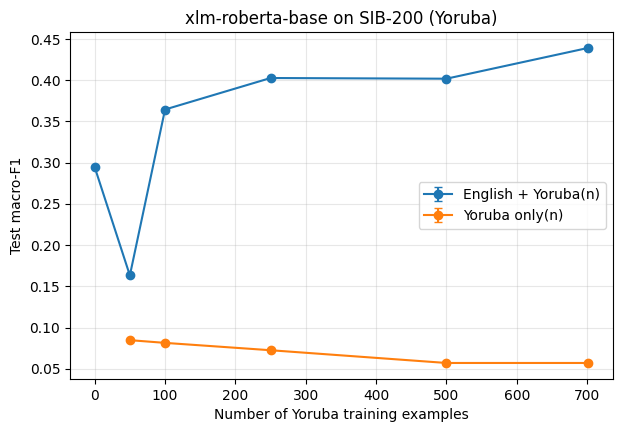

                 test_acc     test_f1    
                     mean std    mean std
use_english n_yo                         
False       50      0.196 NaN   0.085 NaN
            100     0.225 NaN   0.082 NaN
            250     0.201 NaN   0.073 NaN
            500     0.250 NaN   0.057 NaN
            701     0.250 NaN   0.057 NaN
True        0       0.368 NaN   0.295 NaN
            50      0.299 NaN   0.163 NaN
            100     0.431 NaN   0.364 NaN
            250     0.422 NaN   0.403 NaN
            500     0.466 NaN   0.402 NaN
            701     0.461 NaN   0.439 NaN


In [ ]:
import matplotlib.pyplot as plt
df = pd.DataFrame(results)
df = df[df.model == MODEL]
fig, ax = plt.subplots(figsize=(7, 4.5))
for use_en, name in [(True, "English + Yoruba(n)"), (False, "Yoruba only(n)")]:
    g = df[df.use_english == use_en].groupby("n_yo")["test_f1"].agg(["mean", "std"]).fillna(0)
    ax.errorbar(g.index, g["mean"], yerr=g["std"], marker="o", capsize=3, label=name)
ax.set_xlabel("Number of Yoruba training examples"); ax.set_ylabel("Test macro-F1")
ax.set_title(f"{MODEL} on SIB-200 (Yoruba)"); ax.legend(); ax.grid(alpha=.3)
plt.savefig(f"{OUT}/curve_{MODEL.replace('/', '_')}.png", dpi=150, bbox_inches="tight")
plt.show()
print(df.groupby(["use_english", "n_yo"])[["test_acc", "test_f1"]].agg(["mean", "std"]).round(3))

## 8. Next: swap the model
Set `MODEL = "Davlan/afro-xlmr-base"` (verify the exact name on the Hugging Face hub), re-run sections 2, 3, 4, 6, 7, and compare curves.
You must re-run the tokenizer cell because the tokenizer changes with the model.

## Questions to answer in your write-up
1. How much of the Yoruba score at n=0 comes from English transfer alone?
2. At what n does adding English stop helping?
3. Is the gap between conditions larger than the seed std?
4. What changes with AfroXLMR, and why?
5. What are the limitations? (single task, 204 test examples, 3 seeds, fixed hyperparameters)